# 05 - Comparação entre Modelos (SVM, KNN e MLP)

### 1. Carregamento dos resultados salvos em CSV

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

res_dir = Path("../../resultados")
df_svm = pd.read_csv(res_dir / "svm_resultados.csv")
df_knn = pd.read_csv(res_dir / "knn_resultados.csv")
df_mlp = pd.read_csv(res_dir / "mlp_resultados.csv")

df_todos = pd.concat([df_svm, df_knn, df_mlp], ignore_index=True)
df_todos = df_todos.sort_values("F1_macro", ascending=False).reset_index(drop=True)
df_todos.to_csv(res_dir / "comparacao_completa.csv", index=False)

tabela_completa = df_todos[["Modelo", "Config", "Acurácia", "Precisão_macro", "Revocação_macro", "F1_macro"]].copy()
tabela_completa.columns = ["Modelo", "Configuração", "Acurácia", "Precisão (macro)", "Revocação (macro)", "F1-score (macro)"]
tabela_completa

,Modelo,Configuração,Acurácia,Precisão (macro),Revocação (macro),F1-score (macro)
0,MLP,"(128, 64) relu",0.7706 ± 0.0148,0.717740,0.690152,0.697775
1,MLP,"(128, 64) relu alpha=0.01",0.7719 ± 0.0128,0.718586,0.688373,0.696528
2,MLP,"(128, 64, 32) relu",0.7685 ± 0.0183,0.715116,0.687405,0.695776
3,SVM,linear C=1,0.7717 ± 0.0104,0.717709,0.686125,0.695116
4,MLP,"(128, 64) tanh",0.7728 ± 0.0178,0.719487,0.686222,0.694175
5,SVM,rbf C=10,0.7608 ± 0.0112,0.704630,0.685355,0.691689
6,MLP,"(64,) relu",0.7712 ± 0.0133,0.717301,0.682428,0.691376
7,SVM,rbf C=1,0.7715 ± 0.0037,0.726186,0.677963,0.689770
8,KNN,manhattan k=5,0.7177 ± 0.0064,0.664009,0.627600,0.637004
9,KNN,manhattan k=7,0.7226 ± 0.0148,0.676758,0.623391,0.635313


### 2. Tabela comparativa dos melhores modelos (por algoritmo)

In [2]:
df_melhores = (
    df_todos.sort_values("F1_macro", ascending=False)
    .groupby("Modelo", as_index=False)
    .first()
    .sort_values("F1_macro", ascending=False)
    .reset_index(drop=True)
)
df_melhores.to_csv(res_dir / "comparacao_melhores.csv", index=False)

tabela_melhores = df_melhores[["Modelo", "Config", "Acurácia", "Precisão_macro", "Revocação_macro", "F1_macro"]].copy()
tabela_melhores.columns = ["Modelo", "Melhor Configuração", "Acurácia", "Precisão (macro)", "Revocação (macro)", "F1-score (macro)"]
tabela_melhores

,Modelo,Melhor Configuração,Acurácia,Precisão (macro),Revocação (macro),F1-score (macro)
0,MLP,"(128, 64) relu",0.7706 ± 0.0148,0.717740,0.690152,0.697775
1,SVM,linear C=1,0.7717 ± 0.0104,0.717709,0.686125,0.695116
2,KNN,manhattan k=5,0.7177 ± 0.0064,0.664009,0.627600,0.637004


### 3. Gráfico comparativo dos melhores modelos

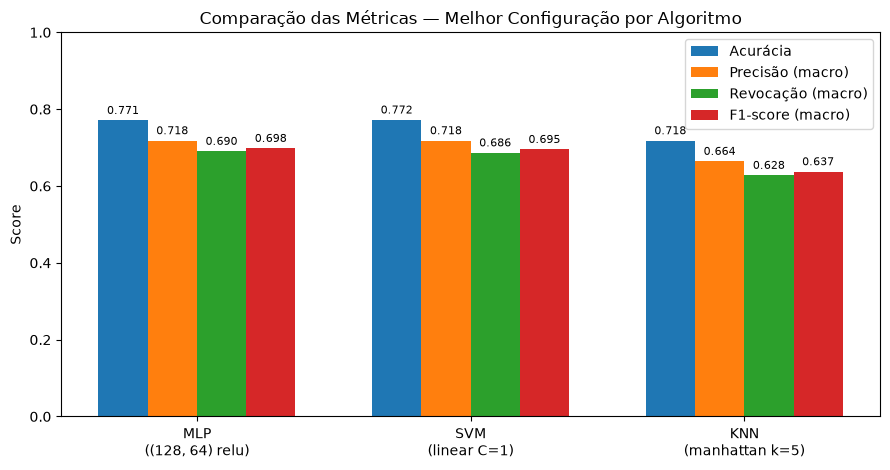

In [3]:
metricas = ["Acurácia_media", "Precisão_macro", "Revocação_macro", "F1_macro"]
rotulos = ["Acurácia", "Precisão (macro)", "Revocação (macro)", "F1-score (macro)"]

x = np.arange(len(df_melhores))
largura = 0.18

fig, ax = plt.subplots(figsize=(9, 4.8))
for i, (col, rotulo) in enumerate(zip(metricas, rotulos)):
    desloc = (i - 1.5) * largura
    bars = ax.bar(x + desloc, df_melhores[col], largura, label=rotulo)
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width() / 2, h + 0.01, f"{h:.3f}", ha="center", va="bottom", fontsize=8)

ax.set_xticks(x)
ax.set_xticklabels([f"{r['Modelo']}\n({r['Config']})" for _, r in df_melhores.iterrows()])
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
ax.set_title("Comparação das Métricas — Melhor Configuração por Algoritmo")
ax.legend(loc="upper right")
plt.tight_layout()
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/comparacao_modelos_melhores.png", dpi=300, bbox_inches="tight")
plt.show()

### 4. Ranking geral de F1-score (macro) entre todas as configurações

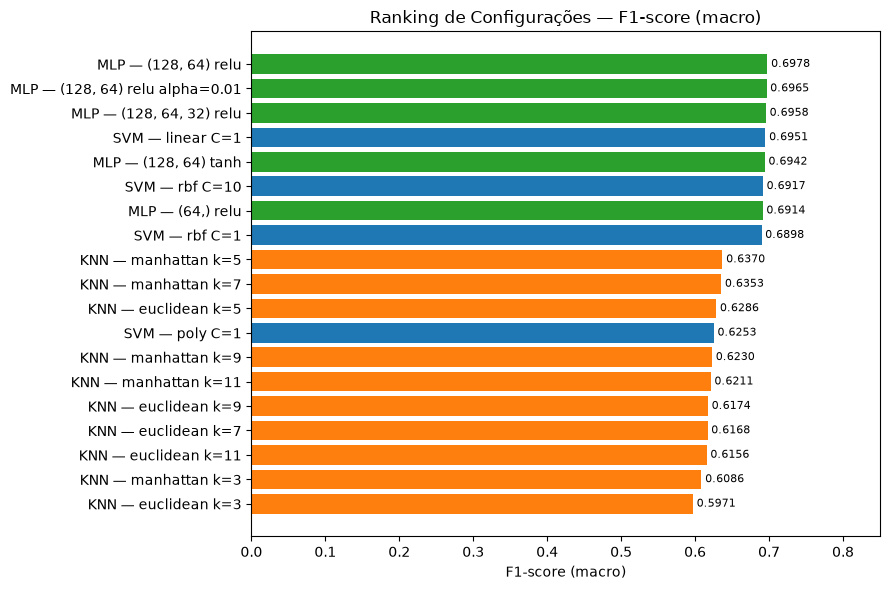

In [4]:
df_rank = df_todos.sort_values("F1_macro", ascending=True).reset_index(drop=True)
cores = {"SVM": "#1f77b4", "KNN": "#ff7f0e", "MLP": "#2ca02c"}

fig, ax = plt.subplots(figsize=(9, 6))
labels = [f"{r['Modelo']} — {r['Config']}" for _, r in df_rank.iterrows()]
colors = [cores[m] for m in df_rank["Modelo"]]

bars = ax.barh(labels, df_rank["F1_macro"], color=colors)
for b in bars:
    w = b.get_width()
    ax.text(w + 0.005, b.get_y() + b.get_height() / 2, f"{w:.4f}", va="center", fontsize=8)

ax.set_xlim(0, 0.85)
ax.set_xlabel("F1-score (macro)")
ax.set_title("Ranking de Configurações — F1-score (macro)")
plt.tight_layout()
Path("../../media").mkdir(parents=True, exist_ok=True)
plt.savefig("../../media/comparacao_modelos_f1.png", dpi=300, bbox_inches="tight")
plt.show()